# POLYNOMIAL REGRESSION MODEL

### 1. IMPORT LIBRARIES

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 2. LOAD DATASET

In [42]:
df = pd.read_csv("../student_scores.csv")

### 3. FEATURES AND TARGET

In [43]:
X = df[["Hours"]]
y = df[["Scores"]]

### 4. TRAIN / TEST SPLIT

In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42
)

### 5. POLYNOMIAL FEATURES

In [45]:
poly = PolynomialFeatures(degree = 2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.fit_transform(X_test)

### 6. TRAIN MODEL

In [46]:
model = LinearRegression()
model.fit(X_train_poly, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


### 7. PREDICTIONS

In [47]:
y_pred = model.predict(X_test_poly)

### 8.EVALUATION

In [48]:
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("r2_Score:", r2_score(y_test, y_pred))

MAE: 1.0368852459016367
MSE: 1.7529141582339114
r2_Score: 0.9980523176019623


### 9. VISUALIZATION

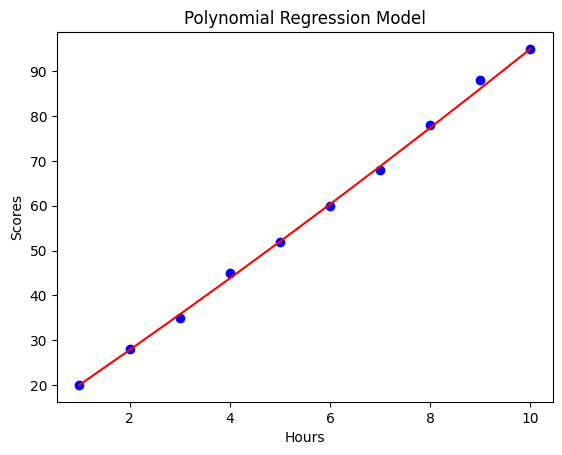

In [49]:
plt.scatter(X, y, color = "blue")

X_plot = X.sort_values(by = "Hours")
X_plot_poly = poly.transform(X_plot)

plt.plot(X_plot, model.predict(X_plot_poly), color = "red")

plt.xlabel("Hours")
plt.ylabel("Scores")
plt.title("Polynomial Regression Model")
plt.show()